In [1]:
import sys
import pandas
import numpy
import sklearn
import matplotlib
import seaborn
import importlib.util
import torch
from pathlib import Path
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02"
)

print("Project exists:", PROJECT_PATH.exists())
print("Notebook folder:", PROJECT_PATH)
print("\nFiles in project:")

for item in PROJECT_PATH.iterdir():
    print(item.name)




Project exists: True
Notebook folder: C:\Users\Dear User\Desktop\my project\p02

Files in project:
Ai.ipynb


In [6]:
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02"
)

DATA_PATH = PROJECT_PATH / "data"
DATA_PATH.mkdir(exist_ok=True)

print("Data folder:", DATA_PATH)
print("Folder created:", DATA_PATH.exists())


Data folder: C:\Users\Dear User\Desktop\my project\p02\data
Folder created: True


In [7]:
from pathlib import Path
from urllib.request import Request, urlopen

DATA_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02\data"
)

DATA_PATH.mkdir(parents=True, exist_ok=True)

url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
dataset_file = DATA_PATH / "aclImdb_v1.tar.gz"

if dataset_file.exists():
    print("Dataset archive already exists:", dataset_file)
else:
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})

    print("Downloading IMDb dataset...")

    with urlopen(request, timeout=120) as response:
        with open(dataset_file, "wb") as output:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                output.write(chunk)

    print("Download completed!")

print("File exists:", dataset_file.exists())

if dataset_file.exists():
    print("File size (MB):", round(dataset_file.stat().st_size / (1024 * 1024), 2))
    

URLError: <urlopen error [WinError 10060] A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond>

In [4]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
error: connection-timeout

× Unable to fetch https://files.pythonhosted.org/packages/24/cc/7f624629846c709ef1c68aa61bfb8d0ae2638cbe265104a1c2f7a630949e/datasets-5.1.0-py3-none-any.whl.metadata
╰─> files.pythonhosted.org didn't respond within 15 seconds

hint: This is probably a temporary issue with the remote server or the network connection. If this error persists, check the network configuration. There may be a firewall or proxy that's preventing the connection.


In [5]:
from pathlib import Path
import importlib.util

DATA_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02\data"
)

print("Existing data files:")
for item in DATA_PATH.iterdir():
    print(item.name, "-", round(item.stat().st_size / (1024 * 1024), 2), "MB")

print("\nDatasets library installed:",
      importlib.util.find_spec("datasets") is not None)


Existing data files:

Datasets library installed: False


In [8]:
import pandas as pd

data = {
    "review": [
        "This movie was fantastic and enjoyable",
        "I really loved this wonderful film",
        "The acting was excellent and the story was great",
        "Amazing movie with brilliant performances",
        "I enjoyed every minute of this film",
        "This movie was terrible and boring",
        "I hated this awful film",
        "The acting was poor and the story was bad",
        "Very disappointing movie and a waste of time",
        "I did not enjoy this film at all",
    ],
    "sentiment": [
        "positive",
        "positive",
        "positive",
        "positive",
        "positive",
        "negative",
        "negative",
        "negative",
        "negative",
        "negative",
    ],
}

df = pd.DataFrame(data)

print("Dataset shape:", df.shape)
display(df)


Dataset shape: (10, 2)


,review,sentiment
0,This movie was fantastic and enjoyable,positive
1,I really loved this wonderful film,positive
2,The acting was excellent and the story was great,positive
3,Amazing movie with brilliant performances,positive
4,I enjoyed every minute of this film,positive
5,This movie was terrible and boring,negative
6,I hated this awful film,negative
7,The acting was poor and the story was bad,negative
8,Very disappointing movie and a waste of time,negative
9,I did not enjoy this film at all,negative


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["review"]
y = df["sentiment"]

vectorizer = TfidfVectorizer()

X_tfidf = vectorizer.fit_transform(X)

print("Original data shape:", X.shape)
print("TF-IDF matrix shape:", X_tfidf.shape)
print("\nFirst 10 features:")
print(vectorizer.get_feature_names_out()[:10])


Original data shape: (10,)
TF-IDF matrix shape: (10, 38)

First 10 features:
['acting' 'all' 'amazing' 'and' 'at' 'awful' 'bad' 'boring' 'brilliant'
 'did']


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(df["review"], df["sentiment"])

print("Model training completed!")
print("Training accuracy:", model.score(df["review"], df["sentiment"]))


Model training completed!
Training accuracy: 1.0


In [11]:
new_reviews = [
    "The movie was wonderful and I loved it",
    "This film was boring and disappointing",
    "The story was great but the acting was terrible",
    "I really enjoyed this amazing movie",
]

predictions = model.predict(new_reviews)

for review, prediction in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted sentiment:", prediction)
    print("-" * 50)
    

Review: The movie was wonderful and I loved it
Predicted sentiment: positive
--------------------------------------------------
Review: This film was boring and disappointing
Predicted sentiment: negative
--------------------------------------------------
Review: The story was great but the acting was terrible
Predicted sentiment: negative
--------------------------------------------------
Review: I really enjoyed this amazing movie
Predicted sentiment: positive
--------------------------------------------------


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    df["review"],
    df["sentiment"],
    test_size=0.3,
    random_state=42,
    stratify=df["sentiment"]
)

baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Training samples: 7
Test samples: 3
Test accuracy: 0.3333333333333333

Classification report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3



In [13]:
results = pd.DataFrame({
    "review": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

results["correct"] = results["actual"] == results["predicted"]

display(results)


,review,actual,predicted,correct
0,This movie was terrible and boring,negative,positive,False
1,Very disappointing movie and a waste of time,negative,positive,False
2,I enjoyed every minute of this film,positive,positive,True


In [14]:
probabilities = baseline_model.predict_proba(X_test)

probability_results = pd.DataFrame({
    "review": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred,
    "negative_probability": probabilities[:, list(baseline_model.classes_).index("negative")],
    "positive_probability": probabilities[:, list(baseline_model.classes_).index("positive")],
})

display(probability_results.round(3))


,review,actual,predicted,negative_probability,positive_probability
0,This movie was terrible and boring,negative,positive,0.377,0.623
1,Very disappointing movie and a waste of time,negative,positive,0.362,0.638
2,I enjoyed every minute of this film,positive,positive,0.472,0.528


In [15]:
from urllib.request import urlopen
from urllib.error import URLError
import socket

url = "https://huggingface.co"

try:
    with urlopen(url, timeout=20) as response:
        print("Connection successful!")
        print("HTTP status:", response.status)
except (URLError, TimeoutError, socket.timeout, OSError) as error:
    print("Connection failed.")
    print("Error:", error)
    

Connection successful!
HTTP status: 200


In [17]:
from urllib.request import Request, urlopen

url = (
    "https://huggingface.co/datasets/"
    "stanfordnlp/imdb/resolve/main/README.md"
)

try:
    request = Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urlopen(request, timeout=30) as response:
        print("Dataset page accessible!")
        print("HTTP status:", response.status)
        print("Content type:", response.headers.get("Content-Type"))

except Exception as error:
    print("Request failed:", type(error).__name__)
    print(error)

Dataset page accessible!
HTTP status: 200
Content type: text/plain; charset=utf-8


In [18]:
from urllib.request import Request, urlopen

url = (
    "https://huggingface.co/datasets/"
    "stanfordnlp/imdb/resolve/main/README.md"
)

request = Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urlopen(request, timeout=30) as response:
    readme = response.read().decode("utf-8")

print(readme[:4000])


---
annotations_creators:
- expert-generated
language_creators:
- expert-generated
language:
- en
license:
- other
multilinguality:
- monolingual
size_categories:
- 10K<n<100K
source_datasets:
- original
task_categories:
- text-classification
task_ids:
- sentiment-classification
paperswithcode_id: imdb-movie-reviews
pretty_name: IMDB
dataset_info:
  config_name: plain_text
  features:
  - name: text
    dtype: string
  - name: label
    dtype:
      class_label:
        names:
          '0': neg
          '1': pos
  splits:
  - name: train
    num_bytes: 33432823
    num_examples: 25000
  - name: test
    num_bytes: 32650685
    num_examples: 25000
  - name: unsupervised
    num_bytes: 67106794
    num_examples: 50000
  download_size: 83446840
  dataset_size: 133190302
configs:
- config_name: plain_text
  data_files:
  - split: train
    path: plain_text/train-*
  - split: test
    path: plain_text/test-*
  - split: unsupervised
    path: plain_text/unsupervised-*
  default: true
train

In [19]:
# کد شماره ۲۷
import json
from urllib.request import Request, urlopen

url = "https://huggingface.co/api/datasets/stanfordnlp/imdb/tree/main?recursive=true"

request = Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urlopen(request, timeout=30) as response:
    files = json.loads(response.read().decode("utf-8"))

for file in files:
    if file.get("type") == "file":
        print(file["path"])
        

.gitattributes
README.md
plain_text/test-00000-of-00001.parquet
plain_text/train-00000-of-00001.parquet
plain_text/unsupervised-00000-of-00001.parquet


In [20]:
# کد شماره ۲۸
from urllib.request import Request, urlopen
from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02\data"
)
DATA_PATH.mkdir(parents=True, exist_ok=True)

base_url = (
    "https://huggingface.co/datasets/"
    "stanfordnlp/imdb/resolve/main/plain_text/"
)

files_to_download = [
    "train-00000-of-00001.parquet",
    "test-00000-of-00001.parquet",
]

for filename in files_to_download:
    save_path = DATA_PATH / filename

    if save_path.exists() and save_path.stat().st_size > 0:
        print(f"Already downloaded: {filename}")
        continue

    url = base_url + filename
    request = Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    print(f"Downloading: {filename}")

    with urlopen(request, timeout=180) as response:
        content = response.read()

    save_path.write_bytes(content)
    print(f"Saved: {save_path}")
    print(f"Size: {save_path.stat().st_size / (1024 * 1024):.2f} MB")

print("Download step finished!")


Downloading: train-00000-of-00001.parquet
Saved: C:\Users\Dear User\Desktop\my project\p02\data\train-00000-of-00001.parquet
Size: 20.01 MB
Downloading: test-00000-of-00001.parquet
Saved: C:\Users\Dear User\Desktop\my project\p02\data\test-00000-of-00001.parquet
Size: 19.52 MB
Download step finished!


In [21]:
# کد شماره ۲۹
import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02\data"
)

train_df = pd.read_parquet(
    DATA_PATH / "train-00000-of-00001.parquet"
)

test_df = pd.read_parquet(
    DATA_PATH / "test-00000-of-00001.parquet"
)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining dataset columns:")
print(train_df.columns.tolist())

print("\nFirst 5 training samples:")
display(train_df.head())


ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

In [22]:
# کد شماره ۳۰
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
error: connection-timeout

× Unable to fetch https://files.pythonhosted.org/packages/54/3c/1783aab1dac28e175dcf26dfc7123725efc474caecaed91e8a34cb89cad0/pyarrow-26.0.0-cp312-cp312-win_amd64.whl.metadata
╰─> files.pythonhosted.org didn't respond within 15 seconds

hint: This is probably a temporary issue with the remote server or the network connection. If this error persists, check the network configuration. There may be a firewall or proxy that's preventing the connection.


In [23]:
# کد شماره ۳۲
%pip install pyarrow --timeout 120 --retries 2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
error: connection-failed

× Failed to connect to files.pythonhosted.org while fetching https://files.pythonhosted.org/packages/54/3c/1783aab1dac28e175dcf26dfc7123725efc474caecaed91e8a34cb89cad0/pyarrow-26.0.0-cp312-cp312-win_amd64.whl.metadata
╰─> the connection was closed without a reply from the server.

hint: Are you connected to the Internet? If so, check whether your system can connect to files.pythonhosted.org before trying again. There may be a firewall or proxy that's preventing the connection.


In [25]:
# کد شماره ۳۳
import json
from urllib.request import Request, urlopen
from urllib.parse import urlencode

params = urlencode({
    "dataset": "stanfordnlp/imdb",
    "config": "plain_text",
    "split": "train",
    "offset": 0,
    "length": 5,
})

url = "https://datasets-server.huggingface.co/rows?" + params

request = Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

try:
    with urlopen(request, timeout=30) as response:
        result = json.loads(response.read().decode("utf-8"))

    print("Total rows:", result.get("num_rows_total"))
    print("Returned rows:", len(result.get("rows", [])))

    for item in result.get("rows", []):
        print(item["row"])

except Exception as error:
    print(type(error).__name__, error)
    

Total rows: 25000
Returned rows: 5
{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex a

In [26]:
# کد شماره ۳۴
import json
import time
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import urlencode

DATA_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02\data"
)
DATA_PATH.mkdir(parents=True, exist_ok=True)


def fetch_reviews(split, offsets, count_per_class):
    reviews = []

    for start in offsets:
        for offset in range(start, start + count_per_class, 100):
            length = min(100, start + count_per_class - offset)

            params = urlencode({
                "dataset": "stanfordnlp/imdb",
                "config": "plain_text",
                "split": split,
                "offset": offset,
                "length": length,
            })

            url = (
                "https://datasets-server.huggingface.co/rows?"
                + params
            )

            request = Request(
                url,
                headers={"User-Agent": "Mozilla/5.0"}
            )

            for attempt in range(3):
                try:
                    with urlopen(request, timeout=60) as response:
                        result = json.loads(
                            response.read().decode("utf-8")
                        )

                    reviews.extend(
                        item["row"] for item in result["rows"]
                    )
                    break

                except Exception:
                    if attempt == 2:
                        raise
                    time.sleep(2)

        print(f"{split}: fetched {len(reviews)} reviews")

    return reviews


# در این دیتاست، بازه‌های ابتدا و انتهای split
# شامل برچسب‌های متفاوت هستند.
train_reviews = fetch_reviews(
    split="train",
    offsets=[0, 12500],
    count_per_class=1000,
)

test_reviews = fetch_reviews(
    split="test",
    offsets=[0, 12500],
    count_per_class=500,
)

# بررسی تعداد و برچسب‌ها
print("\nTraining labels:")
print({
    label: sum(r["label"] == label for r in train_reviews)
    for label in [0, 1]
})

print("\nTesting labels:")
print({
    label: sum(r["label"] == label for r in test_reviews)
    for label in [0, 1]
})

# ذخیرهٔ فایل‌ها
for filename, records in [
    ("train_real.json", train_reviews),
    ("test_real.json", test_reviews),
]:
    output_path = DATA_PATH / filename

    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(records, file, ensure_ascii=False)

    print(f"Saved {filename}: {len(records)} reviews")

print("\nReal dataset download completed!")


train: fetched 1000 reviews
train: fetched 2000 reviews
test: fetched 500 reviews
test: fetched 1000 reviews

Training labels:
{0: 1000, 1: 1000}

Testing labels:
{0: 500, 1: 500}
Saved train_real.json: 2000 reviews
Saved test_real.json: 1000 reviews

Real dataset download completed!


In [27]:
# کد شماره ۳۵
import json
import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\Dear User\Desktop\my project\p02\data"
)

with open(
    DATA_PATH / "train_real.json",
    "r",
    encoding="utf-8"
) as file:
    train_records = json.load(file)

with open(
    DATA_PATH / "test_real.json",
    "r",
    encoding="utf-8"
) as file:
    test_records = json.load(file)

train_df = pd.DataFrame(train_records)
test_df = pd.DataFrame(test_records)

# انتخاب نام‌های واضح برای ستون‌ها
train_df = train_df.rename(
    columns={"text": "review", "label": "sentiment"}
)
test_df = test_df.rename(
    columns={"text": "review", "label": "sentiment"}
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining label distribution:")
print(train_df["sentiment"].value_counts().sort_index())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nSample reviews:")
display(train_df[["review", "sentiment"]].head(3))


Training shape: (2000, 2)
Testing shape: (1000, 2)

Training label distribution:
sentiment
0    1000
1    1000
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64

Sample reviews:


,review,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0


In [28]:
# کد شماره ۳۶
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# ساخت pipeline
baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            stop_words="english",
            ngram_range=(1, 2),
        ),
    ),
    (
        "classifier",
        LogisticRegression(max_iter=1000),
    ),
])

# آموزش مدل
baseline_model.fit(
    train_df["review"],
    train_df["sentiment"],
)

# پیش‌بینی روی داده‌های تست
y_true = test_df["sentiment"]
y_pred = baseline_model.predict(test_df["review"])

# ارزیابی
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Negative", "Positive"],
        digits=4,
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))


Accuracy: 0.84

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8025    0.9020    0.8493       500
    Positive     0.8881    0.7780    0.8294       500

    accuracy                         0.8400      1000
   macro avg     0.8453    0.8400    0.8394      1000
weighted avg     0.8453    0.8400    0.8394      1000

Confusion Matrix:
[[451  49]
 [111 389]]


In [29]:
# کد شماره ۳۷
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

# استفاده از همان داده‌های آموزش و تست
vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
)

X_train = vectorizer.fit_transform(train_df["review"]).toarray()
X_test = vectorizer.transform(test_df["review"]).toarray()

y_train = train_df["sentiment"].to_numpy(dtype=np.float32)
y_test = test_df["sentiment"].to_numpy(dtype=np.int64)

# تبدیل داده‌ها به Tensor
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.int64)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
)

print("Training tensor shape:", X_train_tensor.shape)
print("Testing tensor shape:", X_test_tensor.shape)
print("PyTorch version:", torch.__version__)


Training tensor shape: torch.Size([2000, 10000])
Testing tensor shape: torch.Size([1000, 10000])
PyTorch version: 2.14.1+cpu


In [30]:
# کد شماره ۳۸
import torch
from torch import nn

class SentimentMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


# استفاده از CPU
device = torch.device("cpu")

model = SentimentMLP(
    input_size=X_train_tensor.shape[1]
).to(device)

print(model)
print("\nDevice:", device)
print(
    "\nTotal parameters:",
    sum(p.numel() for p in model.parameters())
)


SentimentMLP(
  (network): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

Device: cpu

Total parameters: 2576769


In [31]:
# کد شماره ۳۹
import torch
from torch import nn

# تابع خطا برای طبقه‌بندی دودویی
criterion = nn.BCEWithLogitsLoss()

# بهینه‌ساز برای به‌روزرسانی وزن‌های شبکه
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001


In [32]:
# کد شماره ۴۰
import time

epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    start_time = time.time()

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # پاک کردن گرادیان‌های قبلی
        optimizer.zero_grad()

        # پیش‌بینی شبکه
        logits = model(batch_X)

        # محاسبه خطا
        loss = criterion(logits, batch_y)

        # محاسبه گرادیان و به‌روزرسانی وزن‌ها
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_X.size(0)

    average_loss = total_loss / len(train_loader.dataset)
    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {average_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

print("\nTraining completed!")

Epoch 1/5 | Loss: 0.5987 | Time: 5.4s
Epoch 2/5 | Loss: 0.1257 | Time: 2.7s
Epoch 3/5 | Loss: 0.0123 | Time: 2.7s
Epoch 4/5 | Loss: 0.0032 | Time: 2.6s
Epoch 5/5 | Loss: 0.0015 | Time: 2.6s

Training completed!


In [33]:
# کد شماره ۴۱
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

model.eval()

with torch.no_grad():
    test_logits = model(X_test_tensor.to(device))
    test_probabilities = torch.sigmoid(test_logits)
    y_pred_mlp = (
        test_probabilities >= 0.5
    ).int().cpu().numpy()

y_true = y_test_tensor.cpu().numpy()

print(
    "Neural Network Accuracy:",
    round(accuracy_score(y_true, y_pred_mlp), 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred_mlp,
        target_names=["Negative", "Positive"],
        digits=4,
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_mlp))

Neural Network Accuracy: 0.827

Classification Report:
              precision    recall  f1-score   support

    Negative     0.7853    0.9000    0.8388       500
    Positive     0.8829    0.7540    0.8134       500

    accuracy                         0.8270      1000
   macro avg     0.8341    0.8270    0.8261      1000
weighted avg     0.8341    0.8270    0.8261      1000

Confusion Matrix:
[[450  50]
 [123 377]]


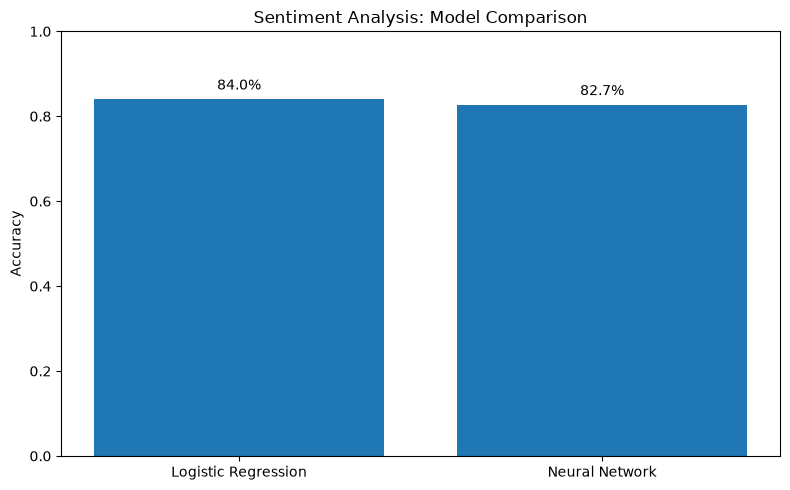

In [34]:

# کد شماره ۴۲
import matplotlib.pyplot as plt
import numpy as np

models = ["Logistic Regression", "Neural Network"]
accuracies = [0.840, 0.827]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.ylim(0.0, 1.0)
plt.ylabel("Accuracy")
plt.title("Sentiment Analysis: Model Comparison")

for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.1%}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()


In [35]:

# کد شماره ۴۳
def predict_sentiment(review_text):
    prediction = baseline_model.predict([review_text])[0]
    probabilities = baseline_model.predict_proba([review_text])[0]

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probabilities[prediction]

    print("Review:", review_text)
    print("Predicted sentiment:", sentiment)
    print(f"Model confidence: {confidence:.2%}")


predict_sentiment(
    "This movie was fantastic, beautifully acted, and very enjoyable."
)

predict_sentiment(
    "This movie was boring, poorly written, and a complete disappointment."
)



Review: This movie was fantastic, beautifully acted, and very enjoyable.
Predicted sentiment: Positive
Model confidence: 72.79%
Review: This movie was boring, poorly written, and a complete disappointment.
Predicted sentiment: Negative
Model confidence: 72.87%


In [36]:

# کد شماره ۴۴
import joblib
from pathlib import Path

project_dir = Path.cwd()

joblib.dump(
    baseline_model,
    project_dir / "sentiment_model.joblib"
)

print("Model saved successfully!")
print("File:", project_dir / "sentiment_model.joblib")


Model saved successfully!
File: c:\Users\Dear User\Desktop\my project\p02\sentiment_model.joblib


In [37]:

# کد شماره ۴۵
import joblib
from pathlib import Path

model_path = Path.cwd() / "sentiment_model.joblib"

loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")

test_reviews = [
    "This movie was absolutely wonderful and entertaining.",
    "This movie was terrible, boring, and disappointing.",
]

for review in test_reviews:
    prediction = loaded_model.predict([review])[0]
    probabilities = loaded_model.predict_proba([review])[0]

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probabilities[prediction]

    print("\nReview:", review)
    print("Sentiment:", sentiment)
    print(f"Confidence: {confidence:.2%}")


Saved model loaded successfully!

Review: This movie was absolutely wonderful and entertaining.
Sentiment: Positive
Confidence: 68.84%

Review: This movie was terrible, boring, and disappointing.
Sentiment: Negative
Confidence: 83.26%


In [ ]:

# کد شماره ۴۸
import subprocess
import sys
from pathlib import Path

project_dir = Path.cwd()
requirements_file = project_dir / "installed_packages.txt"

result = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=True,
)

requirements_file.write_text(
    result.stdout,
    encoding="utf-8",
)

print("Installed package list saved!")
print("Location:", requirements_file)

Installed package list saved!
Location: c:\Users\Dear User\Desktop\my project\p02\installed_packages.txt
